# مشروع التنبؤ بمرض الكوليرا - تنظيف البيانات وبناء النموذج

In [1]:
import pandas as pd
import numpy as np

# ============================================
# 1. قراءة البيانات وحذف الصف الوصفي
# ============================================
df = pd.read_csv("../data/Yemen Cholera Outbreak Epidemiology Data.csv", skiprows=[1])

# ============================================
# 2. تنظيف الأعمدة والتاريخ
# ============================================
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# ============================================
# 3. تحويل البيانات التراكمية إلى حالات جديدة
# ============================================
df['New_Cases'] = df['Cases'].diff()
df['New_Deaths'] = df['Deaths'].diff()

df.iloc[0, df.columns.get_loc('New_Cases')] = 0
df.iloc[0, df.columns.get_loc('New_Deaths')] = 0

# ============================================
# 4. التعامل مع القيم السالبة
# ============================================
df['New_Cases'] = df['New_Cases'].apply(lambda x: max(0, x))
df['New_Deaths'] = df['New_Deaths'].apply(lambda x: max(0, x))

# ============================================
# 5. التجميع الأسبوعي
# ============================================
df.set_index('Date', inplace=True)
weekly_df = df.resample('W-MON').agg({
    'New_Cases': 'sum',
    'New_Deaths': 'sum',
    'Cases': 'last',
    'Deaths': 'last',
    'CFR (%)': 'mean',
    'Attack Rate (per 1000)': 'mean'
}).reset_index()

# ============================================
# 6. ملء القيم المفقودة
# ============================================
weekly_df['New_Cases'] = weekly_df['New_Cases'].fillna(0)
weekly_df['New_Deaths'] = weekly_df['New_Deaths'].fillna(0)

print("=== البيانات الأسبوعية النظيفة ===")
print(weekly_df.head(10))
print(f"\nعدد الأسابيع: {len(weekly_df)}")
print(f"\nالفترة الزمنية: {weekly_df['Date'].min()} إلى {weekly_df['Date'].max()}")

# حفظ البيانات في مجلد المخرجات
weekly_df.to_csv('../outputs/cholera_weekly_cleaned.csv', index=False)
print("\n✅ تم حفظ البيانات النظيفة في: ../outputs/cholera_weekly_cleaned.csv")

=== البيانات الأسبوعية النظيفة ===
        Date  New_Cases  New_Deaths     Cases  Deaths   CFR (%)  \
0 2017-05-22        0.0         0.0   35471.0   361.0  1.000000   
1 2017-05-29    16669.0       110.0   52140.0   471.0  0.900000   
2 2017-06-05    34282.0       210.0   86422.0   681.0  0.800000   
3 2017-06-12    42763.0       261.0  129185.0   942.0  0.733333   
4 2017-06-19    43101.0       228.0  172286.0  1170.0  0.700000   
5 2017-06-26    46512.0       230.0  218798.0  1400.0  0.657143   
6 2017-07-03    50810.0       214.0  269608.0  1614.0  0.600000   
7 2017-07-10    43930.0       118.0  313538.0  1732.0  0.600000   
8 2017-07-17    43053.0        70.0  356591.0  1802.0  0.500000   
9 2017-07-24    39495.0        67.0  396086.0  1869.0  0.500000   

   Attack Rate (per 1000)  
0                1.190000  
1                1.760000  
2                2.555000  
3                3.990000  
4                5.216000  
5                6.742857  
6                8.328571  
7  

In [2]:
import pandas as pd
import numpy as np

# ============================================
# 1. قراءة بيانات الأمطار
# ============================================
rain_df = pd.read_csv('../data/hdx_hapi_rainfall_yem.csv')

print("=== معلومات عامة عن بيانات الأمطار ===")
print(f"عدد الصفوف: {len(rain_df)}")

# ============================================
# 2. تصفية البيانات
# ============================================
national_rain = rain_df[rain_df['admin_level'] == 0].copy()

if len(national_rain) > 0:
    print("\n✅ يوجد بيانات وطنية مباشرة")
    rain_national = national_rain.copy()
else:
    print("\n⚠️ لا يوجد بيانات وطنية، سنجمع المحافظات")
    rain_national = rain_df[rain_df['admin_level'] == 1].copy()

# ============================================
# 3. تنظيف التواريخ
# ============================================
rain_national['start_date'] = pd.to_datetime(rain_national['reference_period_start'])
rain_national['end_date'] = pd.to_datetime(rain_national['reference_period_end'])

# ============================================
# 4. تصفية الفترة الزمنية
# ============================================
rain_national = rain_national[
    (rain_national['start_date'] >= '2017-01-01') & 
    (rain_national['end_date'] <= '2018-12-31')
].copy()

# ============================================
# 5. اختيار الدقة العشرية (dekad)
# ============================================
rain_national = rain_national[rain_national['aggregation_period'] == 'dekad'].copy()

# ============================================
# 6. التجميع على المستوى الوطني
# ============================================
if 'admin1_name' in rain_national.columns and rain_national['admin_level'].max() == 1:
    rain_national_agg = rain_national.groupby(['start_date', 'end_date']).agg({
        'rainfall': 'mean',
        'rainfall_anomaly_pct': 'mean'
    }).reset_index()
    print("\n✅ تم تجميع بيانات المحافظات على المستوى الوطني")
else:
    rain_national_agg = rain_national[['start_date', 'end_date', 'rainfall', 'rainfall_anomaly_pct']].copy()

# ============================================
# 7. إعادة تسمية الأعمدة
# ============================================
rain_national_agg = rain_national_agg.rename(columns={
    'start_date': 'Date',
    'rainfall': 'rainfall_mm',
    'rainfall_anomaly_pct': 'rainfall_anomaly'
})

print(f"\nعدد السجلات: {len(rain_national_agg)}")

# حفظ البيانات في مجلد المخرجات
rain_national_agg.to_csv('../outputs/rainfall_national_weekly.csv', index=False)
print("\n✅ تم حفظ بيانات الأمطار في: ../outputs/rainfall_national_weekly.csv")

=== معلومات عامة عن بيانات الأمطار ===
عدد الصفوف: 44742

⚠️ لا يوجد بيانات وطنية، سنجمع المحافظات

عدد السجلات: 0

✅ تم حفظ بيانات الأمطار في: ../outputs/rainfall_national_weekly.csv


In [3]:
# ============================================
# 1. قراءة بيانات النازحين
# ============================================
idp_df = pd.read_csv('../data/hdx_hapi_idps_yem.csv')

print("=== معلومات عامة عن بيانات النازحين ===")
print(f"عدد الصفوف: {len(idp_df)}")

# ============================================
# 2. تصفية البيانات
# ============================================
idp_national = idp_df[idp_df['admin_level'] == 0].copy()

if len(idp_national) == 0:
    print("\n⚠️ لا يوجد بيانات وطنية، سنجمع المحافظات")
    idp_national = idp_df[idp_df['admin_level'] == 1].copy()

# ============================================
# 3. تنظيف التواريخ
# ============================================
idp_national['start_date'] = pd.to_datetime(idp_national['reference_period_start'])
idp_national['end_date'] = pd.to_datetime(idp_national['reference_period_end'])

# ============================================
# 4. تصفية الفترة الزمنية
# ============================================
idp_national = idp_national[
    (idp_national['start_date'] >= '2017-01-01') & 
    (idp_national['end_date'] <= '2018-12-31')
].copy()

# ============================================
# 5. التجميع على المستوى الوطني
# ============================================
if 'admin1_name' in idp_national.columns and idp_national['admin_level'].max() == 1:
    idp_national_agg = idp_national.groupby(['start_date', 'end_date']).agg({
        'population': 'sum'
    }).reset_index()
    print("\n✅ تم تجميع بيانات المحافظات على المستوى الوطني")
else:
    idp_national_agg = idp_national[['start_date', 'end_date', 'population']].copy()

# ============================================
# 6. إعادة تسمية الأعمدة
# ============================================
idp_national_agg = idp_national_agg.rename(columns={
    'start_date': 'Date',
    'population': 'total_idps'
})

print(f"\nعدد السجلات: {len(idp_national_agg)}")

# حفظ البيانات في مجلد المخرجات
idp_national_agg.to_csv('../outputs/idps_national.csv', index=False)
print("\n✅ تم حفظ بيانات النازحين في: ../outputs/idps_national.csv")

=== معلومات عامة عن بيانات النازحين ===
عدد الصفوف: 5613

عدد السجلات: 14

✅ تم حفظ بيانات النازحين في: ../outputs/idps_national.csv


In [4]:
# ============================================
# 1. قراءة البيانات النظيفة
# ============================================
cholera_weekly = pd.read_csv('../outputs/cholera_weekly_cleaned.csv')
rain_national = pd.read_csv('../outputs/rainfall_national_weekly.csv')
idps_national = pd.read_csv('../outputs/idps_national.csv')

for df in [cholera_weekly, rain_national, idps_national]:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df['Date'] = df['Date'].astype('datetime64[ns]')

# =============================================
# 2. دمج بيانات الكوليرا مع الأمطار
# ============================================
merged_df = pd.merge_asof(
    cholera_weekly.sort_values('Date'),
    rain_national.sort_values('Date'),
    on='Date',
    direction='nearest',
    tolerance=pd.Timedelta('7 days')
)

# ============================================
# 3. دمج بيانات النازحين
# ============================================
merged_df = pd.merge_asof(
    merged_df.sort_values('Date'),
    idps_national.sort_values('Date'),
    on='Date',
    direction='backward',
    tolerance=pd.Timedelta('90 days')
)

# ============================================
# 4. ملء القيم المفقودة
# ============================================
merged_df['rainfall_mm'] = merged_df['rainfall_mm'].ffill()
merged_df['rainfall_anomaly'] = merged_df['rainfall_anomaly'].ffill()
merged_df['total_idps'] = merged_df['total_idps'].ffill()

merged_df['rainfall_mm'] = merged_df['rainfall_mm'].fillna(0)
merged_df['rainfall_anomaly'] = merged_df['rainfall_anomaly'].fillna(0)
merged_df['total_idps'] = merged_df['total_idps'].fillna(0)

print(f"\nعدد الصفوف: {len(merged_df)}")

# حفظ البيانات في مجلد المخرجات
merged_df.to_csv('../outputs/merged_data_final.csv', index=False)
print("\n✅ تم حفظ البيانات المدمجة في: ../outputs/merged_data_final.csv")


عدد الصفوف: 59

✅ تم حفظ البيانات المدمجة في: ../outputs/merged_data_final.csv


In [5]:
# ============================================
# 1. قراءة البيانات المدمجة
# ============================================
df = pd.read_csv('../outputs/merged_data_final.csv')
df['Date'] = pd.to_datetime(df['Date'])

# ============================================
# 2. إنشاء Lag Features
# ============================================
df['cases_lag_1'] = df['New_Cases'].shift(1)
df['cases_lag_2'] = df['New_Cases'].shift(2)
df['cases_lag_3'] = df['New_Cases'].shift(3)
df['cases_lag_4'] = df['New_Cases'].shift(4)

# ============================================
# 3. إنشاء Rolling Statistics
# ============================================
df['cases_rolling_mean_4'] = df['New_Cases'].rolling(window=4).mean()
df['cases_rolling_mean_8'] = df['New_Cases'].rolling(window=8).mean()

# ============================================
# 4. إنشاء ميزات الأمطار المتأخرة
# ============================================
df['rainfall_lag_1'] = df['rainfall_mm'].shift(1)
df['rainfall_lag_2'] = df['rainfall_mm'].shift(2)
df['rainfall_lag_3'] = df['rainfall_mm'].shift(3)

df['rainfall_rolling_mean_4'] = df['rainfall_mm'].rolling(window=4).mean()

# ============================================
# 5. إنشاء ميزات النازحين
# ============================================
df['idps_change'] = df['total_idps'].pct_change()

# ============================================
# 6. إنشاء ميزات زمنية
# ============================================
df['week_of_year'] = df['Date'].dt.isocalendar().week
df['month'] = df['Date'].dt.month

df = df.fillna(0)

print(f"\nعدد الأعمدة: {len(df.columns)}")

# حفظ البيانات في مجلد المخرجات
df.to_csv('../outputs/final_features.csv', index=False)
print("\n✅ تم حفظ البيانات مع الميزات في: ../outputs/final_features.csv")


عدد الأعمدة: 25

✅ تم حفظ البيانات مع الميزات في: ../outputs/final_features.csv



✅ تم تدريب النموذج بنجاح!

=== نتائج تقييم النموذج ===
متوسط الخطأ المطلق (MAE): 2645.26 حالة
جذر متوسط مربع الخطأ (RMSE): 5290.81 حالة


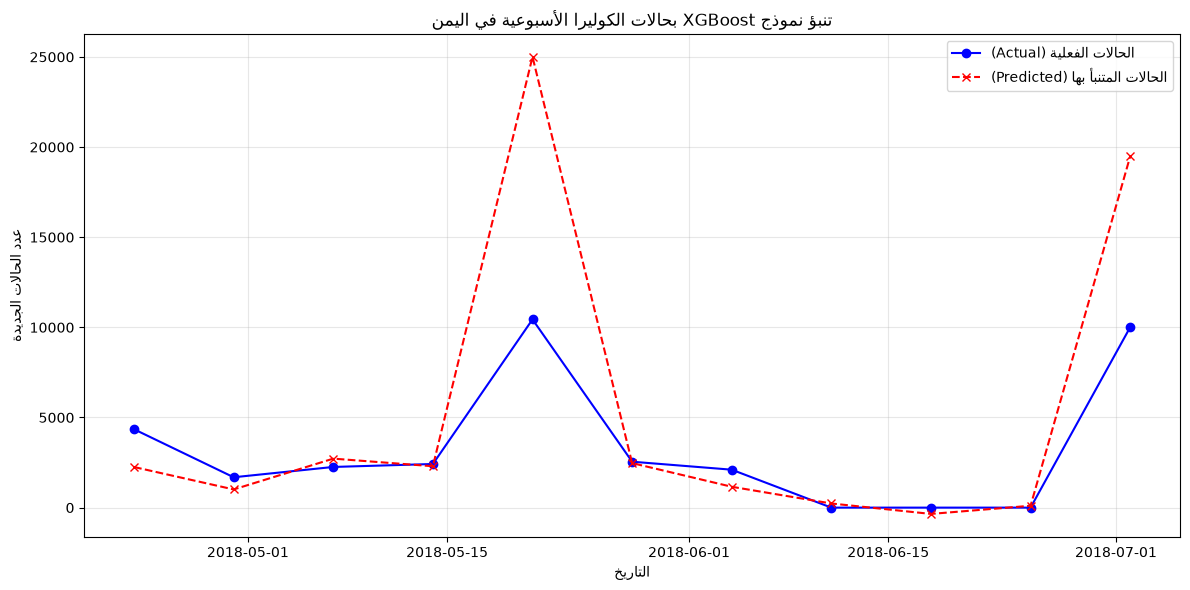

C:\Users\TAHA\AppData\Local\Temp\ipykernel_14976\3262263947.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')


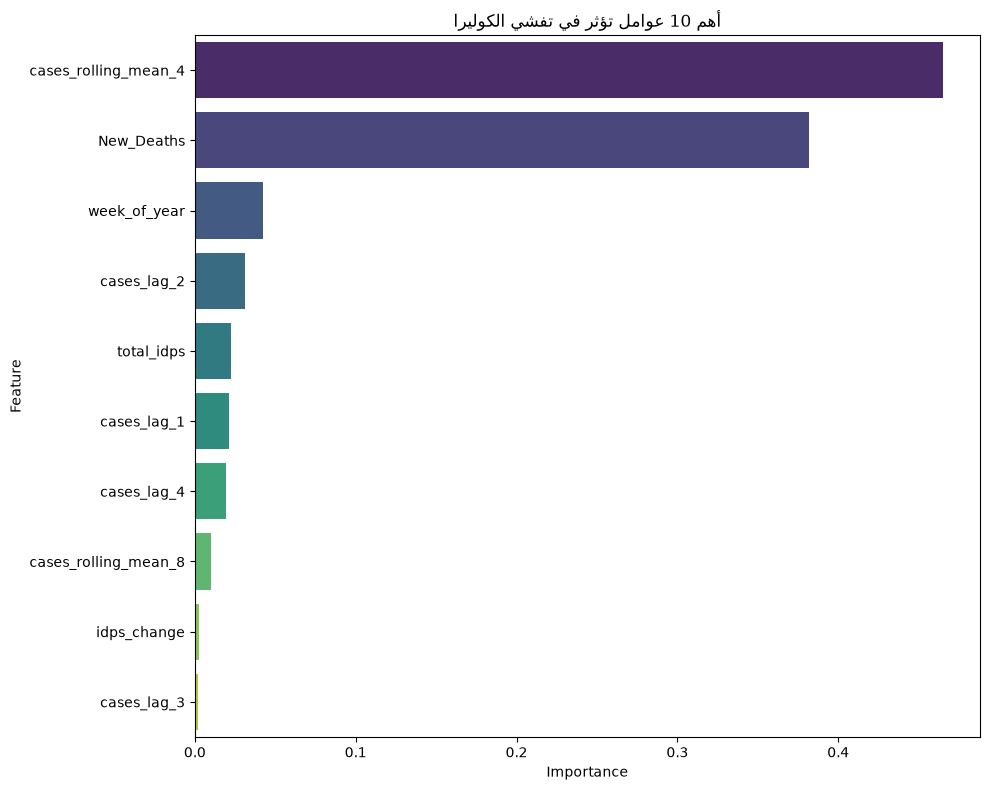


=== ترتيب أهم 5 عوامل ===
             Feature  Importance
cases_rolling_mean_4    0.464907
          New_Deaths    0.382076
        week_of_year    0.042635
         cases_lag_2    0.031430
          total_idps    0.022763


In [6]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# 1. تحميل البيانات وتحديد المتغيرات
# ============================================
df = pd.read_csv('../outputs/final_features.csv')
df['Date'] = pd.to_datetime(df['Date'])

target = 'New_Cases'
features_to_drop = ['Date', 'Cases', 'Deaths', 'CFR (%)', 'Attack Rate (per 1000)']
features = [col for col in df.columns if col not in features_to_drop and col != target]

X = df[features]
y = df[target]

X = X.iloc[4:]
y = y.iloc[4:]
dates = df['Date'].iloc[4:]

# تنظيف الميزات النصية
text_columns = X.select_dtypes(include=["object", "str"]).columns.tolist()
X = X.drop(columns=text_columns)
features = X.columns.tolist()

# ============================================
# 2. التقسيم الزمني (Time-Based Split)
# ============================================
split_index = int(len(X) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
dates_test = dates.iloc[split_index:]

# ============================================
# 3. بناء وتدريب نموذج XGBoost
# ============================================
model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)
print("\n✅ تم تدريب النموذج بنجاح!")

# ============================================
# 4. التقييم (Evaluation)
# ============================================
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n=== نتائج تقييم النموذج ===")
print(f"متوسط الخطأ المطلق (MAE): {mae:.2f} حالة")
print(f"جذر متوسط مربع الخطأ (RMSE): {rmse:.2f} حالة")

# ============================================
# 5. رسم النتائج
# ============================================
plt.figure(figsize=(12, 6))
plt.plot(dates_test, y_test, label='الحالات الفعلية (Actual)', color='blue', marker='o')
plt.plot(dates_test, y_pred, label='الحالات المتنبأ بها (Predicted)', color='red', marker='x', linestyle='--')
plt.title('تنبؤ نموذج XGBoost بحالات الكوليرا الأسبوعية في اليمن')
plt.xlabel('التاريخ')
plt.ylabel('عدد الحالات الجديدة')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================
# 6. تحليل أهمية الميزات
# ============================================
importance = model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('أهم 10 عوامل تؤثر في تفشي الكوليرا')
plt.tight_layout()
plt.show()

print("\n=== ترتيب أهم 5 عوامل ===")
print(feature_importance_df.head(5).to_string(index=False))

In [7]:
# ============================================
# تحويل التنبؤات إلى نظام إنذار مبكر (Alert System)
# ============================================
threshold_yellow = 5000
threshold_red = 15000

def get_alert_level(predicted_cases):
    if predicted_cases >= threshold_red:
        return "🔴 أحمر (تفشي حاد - تدخل فوري)"
    elif predicted_cases >= threshold_yellow:
        return "🟡 أصفر (تأهب - مراقبة مكثفة)"
    else:
        return "🟢 أخضر (وضع طبيعي)"

last_prediction = y_pred[-1]
alert_status = get_alert_level(last_prediction)

print(f"\n=== تقرير الإنذار المبكر للأسبوع القادم ===")
print(f"عدد الحالات المتوقع: {last_prediction:.0f} حالة")
print(f"مستوى الإنذار: {alert_status}")
print(f"الإجراء المقترح: {'تجهيز فرق الاستجابة السريعة وتوزيع الكلور' if 'أحمر' in alert_status else 'مراقبة مصادر المياه'}")


=== تقرير الإنذار المبكر للأسبوع القادم ===
عدد الحالات المتوقع: 19481 حالة
مستوى الإنذار: 🔴 أحمر (تفشي حاد - تدخل فوري)
الإجراء المقترح: تجهيز فرق الاستجابة السريعة وتوزيع الكلور


In [8]:
import joblib

# حفظ النموذج في مجلد المخرجات
joblib.dump(model, '../outputs/cholera_model.pkl')
print("\n✅ تم حفظ النموذج في: ../outputs/cholera_model.pkl")

# حفظ قائمة الميزات في مجلد المخرجات
joblib.dump(features, '../outputs/features_list.pkl')
print("✅ تم حفظ قائمة الميزات في: ../outputs/features_list.pkl")


✅ تم حفظ النموذج في: ../outputs/cholera_model.pkl
✅ تم حفظ قائمة الميزات في: ../outputs/features_list.pkl
